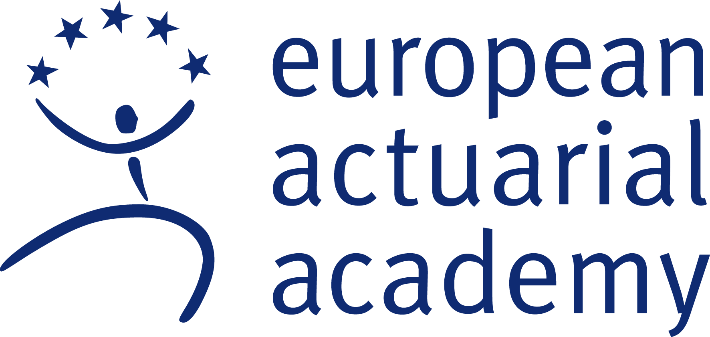

<p style="font-size:17px; text-align:left;"><i>EAA Web Session E0595, GenAI Beyond the Basics: Advanced Concepts for Actuaries, 07 December 2026</i></p>
<p style="font-size:25px; text-align:left; font-weight:bold;">Notebook 6: Agentic AI, from Single Agents to Multi-Agent Systems</p>
<p style="font-size:16px; text-align:left; margin-bottom: 15px;">Dr Simon Hatzesberger<br>Programme slot: 11:15–11:55, Outlook 11:55–12:10 CET</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/genai-beyond-the-basics-20261207/blob/main/notebooks/06_agentic_ai.ipynb) &nbsp; Notebook `06_agentic_ai.ipynb` of the repository <https://github.com/simonhatzesberger/genai-beyond-the-basics-20261207>

So far each technique answered a **single** request. **Agentic AI** gives a model *tools*, a *loop* and some *state*,
so that it can decide which actions to take, observe the results and keep going until a goal is reached. Several such
agents, each with its own role, can be combined into a **multi-agent system**. This notebook builds a single agent
from scratch in plain Python, so that every step is visible, and then a multi-agent system that migrates legacy
actuarial **R code to Python**, the case study of Hatzesberger & Nonneman (2026).

**Contents**
1. [Concept and purpose](#agentic-ai-concept)
2. [Setup](#setup)
3. [Use case 1: a tool-using actuarial agent](#single-agent)
4. [Use case 2: a multi-agent system that migrates R code to Python](#multi-agent)
5. [Guardrails, frameworks and further resources](#agentic-ai-further-applications-and-resources)
6. [Outlook: combining the building blocks](#outlook)

<h1 id="agentic-ai-concept"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
1. Concept and Purpose
</h1>

An **agent** is an LLM placed inside a loop: it reasons about the goal, optionally **calls a tool** (notebook 03),
reads the result, and repeats until it can answer or a limit is reached. This *reason → act → observe* pattern is
often called **ReAct**. Four ingredients make an agent:

| Ingredient | In this notebook |
|---|---|
| **Model** | `gpt-6-luna` (and `gpt-6-sol` for the hardest steps of section 4), deciding what to do next |
| **Tools** | Python functions the model may request: database lookups, a calculator, file and test tools |
| **Loop** | our code calls the model, runs the requested tools, returns the results, and repeats |
| **State and limits** | the conversation so far, a step cap, a cost tally, and a trace of every action |

A **multi-agent system** coordinates several specialised agents, each with its own instructions, tools and model, so
that each can focus on one role: in section 4, one agent analyses legacy R code, one translates it, one compiles it,
one runs the tests and one writes the report.

#### Workflows versus agents

Not every LLM application needs an agent. Anthropic's widely cited guide *Building effective agents* distinguishes
**workflows**, in which code fixes the path, from **agents**, in which the model decides the path:

| Pattern | Who decides the next step | Example in this session |
|---|---|---|
| Prompt chaining | code | extract → check → summarise |
| Routing | a classifier, then code | triage of customer messages (notebook 01) |
| Parallelisation | code | ten contracts at once (notebook 02) |
| Fixed graph of specialised agents with feedback loops | code, on tool results | R-to-Python migration (section 4) |
| Autonomous agent | the model, within limits | tool loop (section 3) |

A good rule of thumb for regulated work: **use the simplest pattern that solves the task**, let code control
everything that can be controlled, and give the model freedom only where it adds value.

<div style="background-color: #f2f2f2; border-left: 4px solid #888888; padding-left: 10px; padding-right: 10px; padding-bottom: 1px; padding-top: 6px;">
<p style="font-weight: bold"><b>Note</b></p>

**Agent risks to manage.** *Runaway loops and cost:* cap the number of steps, retries and spend. *Wrong or
hallucinated tool calls:* validate arguments, expose only allow-listed tools. *Prompt injection:* text in documents,
code comments or tool results can try to redirect the agent; never let it trigger irreversible actions. *Code written
by agents:* run it fenced, never with your credentials in reach. *Auditability:* log the full trace so that every
decision can be reconstructed.

</div>

<h1 id="setup"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
2. Setup
</h1>

In [1]:
# ── Setup: run this cell first ───────────────────────────────────────────────────────────────
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_RAW = "https://raw.githubusercontent.com/simonhatzesberger/genai-beyond-the-basics-20261207/main/notebooks/"

import ast
import json
import math
import operator
import shutil
import sqlite3
import tempfile
import time

import numpy as np
import pandas as pd
from openai import OpenAI


def load_openai_api_key(name: str = "OPENAI_API_KEY", file_path: str = "openai_api_key.txt") -> str | None:
    """Look for the key in Colab Secrets, then in an environment variable, then in a local text file."""
    try:
        from google.colab import userdata  # only available in Colab
        value = userdata.get(name)
        if value:
            return value.strip()
    except Exception:
        pass
    if os.getenv(name):
        return os.getenv(name).strip()
    for candidate in (Path(file_path), Path("..") / file_path):
        if candidate.exists():
            return candidate.read_text(encoding="utf-8").strip()
    return None


api_key = load_openai_api_key()
client = OpenAI(api_key=api_key or "no-key-found")   # the key's value is never printed

MODEL = "gpt-6-luna"           # OpenAI's current small model (checked 22 Nov 2026: no announced shutdown date)
REASONING = {"effort": "low"}  # always set the reasoning effort explicitly (the default is "medium")


def data_file(name: str) -> Path:
    """A data file of this notebook: from data/ next to it, otherwise downloaded once from GitHub (e.g. in Colab)."""
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + "data/" + name, path)
        print(f"Downloaded data/{name} from GitHub.")
    return path


# List prices of MODEL in USD per 1M tokens (OpenAI pricing page, as of 22 Nov 2026)
PRICE_INPUT, PRICE_CACHED_INPUT, PRICE_OUTPUT = 0.10, 0.01, 0.50


def cost_usd(response) -> float:
    """Cost of one Responses API call at the list prices above (reasoning tokens are billed as output)."""
    u = response.usage
    cached = getattr(u.input_tokens_details, "cached_tokens", 0) or 0
    return ((u.input_tokens - cached) * PRICE_INPUT + cached * PRICE_CACHED_INPUT
            + u.output_tokens * PRICE_OUTPUT) / 1e6

print("Running in", "Google Colab" if IN_COLAB else "a local Python " + sys.version.split()[0])
print("OpenAI API key:", "found" if api_key else "NOT found - you can read the saved outputs, but API calls will fail "
      "(see 00_setup_check.ipynb)")
print("Model:", MODEL, "| reasoning effort:", REASONING["effort"])

Running in a local Python 3.13.1
OpenAI API key: found
Model: gpt-6-luna | reasoning effort: low


<h1 id="single-agent"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
3. Use Case 1: A Tool-Using Actuarial Agent
</h1>

We build a single agent that answers multi-step questions about the PKV mortality tables of notebook 03, for
example *"what is the probability that a 65-year-old man survives the next three years?"*. It needs data (the
mortality table) **and** arithmetic (a product of survival probabilities), so we give it three tools:

1. `list_tables`: which tables exist (so the agent never has to guess a name),
2. `fetch_probabilities`: the read-only database lookup from notebook 03,
3. `calculate`: a **safe calculator** that evaluates arithmetic only. It parses the expression and allows numbers,
   `+ - * / **`, parentheses and a few functions (`prod`, `sum`, `sqrt`, `exp`, `log`, `round`), and nothing else:
   no imports, no file access, no Python built-ins. Never give an agent `eval()` on arbitrary code.

In [2]:
DB_PATH = data_file("mortality_tables.sqlite")
DB_URI = f"file:{DB_PATH.as_posix()}?mode=ro"          # read-only


def list_tables() -> list[str]:
    with sqlite3.connect(DB_URI, uri=True) as conn:
        return [r[0] for r in conn.execute("SELECT DISTINCT mortality_table FROM mortality_table ORDER BY 1")]


def fetch_probabilities(mortality_table: str, start_age: int, end_age: int, sex: str) -> list[dict] | dict:
    if mortality_table not in list_tables():
        return {"error": f"Unknown table {mortality_table!r}. Available: {list_tables()}"}
    with sqlite3.connect(DB_URI, uri=True) as conn:
        rows = conn.execute(
            "SELECT age, probability FROM mortality_table WHERE mortality_table=? AND gender=? "
            "AND age BETWEEN ? AND ? ORDER BY age", (mortality_table, sex.upper(), int(start_age), int(end_age))
        ).fetchall()
    return [{"age": a, "q": q} for a, q in rows]


_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
        ast.Pow: operator.pow, ast.USub: operator.neg, ast.UAdd: operator.pos}
_FUNCS = {"prod": math.prod, "sum": sum, "sqrt": math.sqrt, "exp": math.exp, "log": math.log, "round": round}


def calculate(expression: str) -> dict:
    """Evaluate an arithmetic expression safely (no names, no attributes, no imports)."""
    def ev(node):
        if isinstance(node, ast.Expression):
            return ev(node.body)
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _OPS:
            if isinstance(node.op, ast.Pow) and abs(ev(node.right)) > 100:
                raise ValueError("exponent too large")
            return _OPS[type(node.op)](ev(node.left), ev(node.right))
        if isinstance(node, ast.UnaryOp) and type(node.op) in _OPS:
            return _OPS[type(node.op)](ev(node.operand))
        if isinstance(node, (ast.List, ast.Tuple)):
            return [ev(e) for e in node.elts]
        if (isinstance(node, ast.Call) and isinstance(node.func, ast.Name) and node.func.id in _FUNCS
                and not node.keywords):
            return _FUNCS[node.func.id](*[ev(a) for a in node.args])
        raise ValueError(f"not allowed: {type(node).__name__}")
    try:
        return {"result": ev(ast.parse(expression, mode="eval"))}
    except Exception as exc:
        return {"error": f"{type(exc).__name__}: {exc}"}


print(list_tables())
print(calculate("prod([1 - 0.01, 1 - 0.02])"), calculate("__import__('os').remove('x')"))

['PKV-Sterbetafel 2022', 'PKV-Sterbetafel 2023', 'PKV-Sterbetafel 2024', 'PKV-Sterbetafel 2025']
{'result': 0.9702} {'error': 'ValueError: not allowed: Call'}


The tools are described to the model as JSON schemas, exactly as in notebook 03. The **allow-list** `TOOL_IMPL`
is the only bridge between the model's requests and our code: anything not in it cannot be executed.

In [3]:
TOOL_IMPL = {"list_tables": list_tables, "fetch_probabilities": fetch_probabilities, "calculate": calculate}

AGENT_TOOLS = [
    {"type": "function", "name": "list_tables", "strict": True,
     "description": "List the names of the available mortality tables.",
     "parameters": {"type": "object", "properties": {}, "required": [], "additionalProperties": False}},
    {"type": "function", "name": "fetch_probabilities", "strict": True,
     "description": "Fetch one-year death probabilities q_x for a range of ages from one mortality table.",
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {"mortality_table": {"type": "string"},
                                   "start_age": {"type": "integer"}, "end_age": {"type": "integer"},
                                   "sex": {"type": "string", "enum": ["MALE", "FEMALE"]}},
                    "required": ["mortality_table", "start_age", "end_age", "sex"]}},
    {"type": "function", "name": "calculate", "strict": True,
     "description": "Evaluate an arithmetic expression, e.g. prod([1-0.0064, 1-0.0071]). "
                    "Allowed: numbers, + - * / **, parentheses, prod, sum, sqrt, exp, log, round.",
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {"expression": {"type": "string"}}, "required": ["expression"]}},
]

AGENT_INSTRUCTIONS = """You are an actuarial assistant with tools for German PKV mortality tables.
Use the tools for every number: look data up with fetch_probabilities and compute with calculate, never from memory.
If something cannot be answered from the tools, say so. Finish with a short answer that states the figures used."""

MAX_AGENT_STEPS = 8   # guardrail: hard cap on model calls per question


def run_agent(question: str, verbose: bool = True) -> dict:
    """The agent loop: call the model, execute requested tools, feed results back, until it answers or hits the cap."""
    conversation = [{"role": "user", "content": question}]
    trace, spent = [], 0.0
    for step in range(1, MAX_AGENT_STEPS + 1):
        resp = client.responses.create(model=MODEL, reasoning=REASONING, instructions=AGENT_INSTRUCTIONS,
                                       input=conversation, tools=AGENT_TOOLS)
        spent += cost_usd(resp)
        conversation += resp.output
        calls = [item for item in resp.output if item.type == "function_call"]
        if not calls:
            return {"answer": resp.output_text, "steps": step, "trace": trace, "cost_usd": spent}
        for call in calls:
            args = json.loads(call.arguments)
            result = TOOL_IMPL[call.name](**args) if call.name in TOOL_IMPL else {"error": "tool not allowed"}
            trace.append({"step": step, "tool": call.name, "args": args, "result": result})
            if verbose:
                print(f"  [step {step}] {call.name}({args}) -> {str(result)[:90]}")
            conversation.append({"type": "function_call_output", "call_id": call.call_id,
                                 "output": json.dumps(result)})
    return {"answer": "[stopped: step limit reached]", "steps": MAX_AGENT_STEPS, "trace": trace, "cost_usd": spent}

#### The agent at work

The cell prints the **trace**: every tool call with its arguments and result. The agent itself decides which tables
to look up and what to calculate.

In [4]:
question = ("Using the 'PKV-Sterbetafel 2025' table, what is the probability that a 65-year-old man survives "
            "the next 3 full years? Show the yearly death probabilities you used and the result in percent.")

print("Agent trace:")
result = run_agent(question)
print(f"\nFinal answer ({result['steps']} model calls, USD {result['cost_usd']:.5f}):\n{result['answer']}")

Agent trace:


  [step 1] list_tables({}) -> ['PKV-Sterbetafel 2022', 'PKV-Sterbetafel 2023', 'PKV-Sterbetafel 2024', 'PKV-Sterbetafel 


  [step 2] fetch_probabilities({'mortality_table': 'PKV-Sterbetafel 2025', 'start_age': 65, 'end_age': 67, 'sex': 'MALE'}) -> [{'age': 65, 'q': 0.006425}, {'age': 66, 'q': 0.007037}, {'age': 67, 'q': 0.007701}]


  [step 3] calculate({'expression': '(1-0.006425)*(1-0.007037)*(1-0.007701)*100'}) -> {'result': 97.89855354038049}



Final answer (4 model calls, USD 0.00025):
Using the yearly death probabilities for a 65-year-old man and the following ages:

- Age 65: 0.006425
- Age 66: 0.007037
- Age 67: 0.007701

The probability of surviving all three years is \((1-0.006425)(1-0.007037)(1-0.007701)\), or **97.8986%**.


#### Code checks the agent

The trace makes the answer auditable, and because the calculation is simple, we can recompute it independently:

In [5]:
q = [row["q"] for row in fetch_probabilities("PKV-Sterbetafel 2025", 65, 67, "MALE")]
print("q_65..q_67 :", q)
print(f"3-year survival probability (recomputed): {math.prod(1 - x for x in q):.4%}")

q_65..q_67 : [0.006425, 0.007037, 0.007701]
3-year survival probability (recomputed): 97.8986%


#### A question that needs several steps

The next question needs two tables, two ranges of ages and a comparison. Watch how the agent plans its tool calls,
and that it asks `list_tables` first when it is unsure which tables exist.

In [6]:
question = ("For a 60-year-old woman, compare the probability of surviving 10 years under the oldest and the newest "
            "PKV mortality table in the database. By how many percentage points did it change?")

print("Agent trace:")
result = run_agent(question)
print(f"\nFinal answer ({result['steps']} model calls, USD {result['cost_usd']:.5f}):\n{result['answer']}")

for table in ("PKV-Sterbetafel 2022", "PKV-Sterbetafel 2025"):
    q = [row["q"] for row in fetch_probabilities(table, 60, 69, "FEMALE")]
    print(f"Recomputed, {table}: {math.prod(1 - x for x in q):.4%}")

Agent trace:


  [step 1] list_tables({}) -> ['PKV-Sterbetafel 2022', 'PKV-Sterbetafel 2023', 'PKV-Sterbetafel 2024', 'PKV-Sterbetafel 


  [step 2] fetch_probabilities({'mortality_table': 'PKV-Sterbetafel 2022', 'start_age': 60, 'end_age': 69, 'sex': 'FEMALE'}) -> [{'age': 60, 'q': 0.002647}, {'age': 61, 'q': 0.002906}, {'age': 62, 'q': 0.003187}, {'age
  [step 2] fetch_probabilities({'mortality_table': 'PKV-Sterbetafel 2025', 'start_age': 60, 'end_age': 69, 'sex': 'FEMALE'}) -> [{'age': 60, 'q': 0.002488}, {'age': 61, 'q': 0.002785}, {'age': 62, 'q': 0.003118}, {'age


  [step 3] calculate({'expression': 'prod([1-0.002647,1-0.002906,1-0.003187,1-0.003484,1-0.003795,1-0.004092,1-0.004406,1-0.004751,1-0.005149,1-0.005618])'}) -> {'result': 0.9606744144675192}


  [step 4] calculate({'expression': 'prod([1-0.002488,1-0.002785,1-0.003118,1-0.003483,1-0.003795,1-0.004092,1-0.004406,1-0.004751,1-0.005149,1-0.005618])'}) -> {'result': 0.9610116475747809}


  [step 5] calculate({'expression': '(0.9610116475747809-0.9606744144675192)*100'}) -> {'result': 0.033723310726163636}



Final answer (6 model calls, USD 0.00062):
Using the oldest table (PKV-Sterbetafel 2022) and newest (2025), a 60-year-old woman’s 10-year survival probability rises from **96.0674%** to **96.1012%**—an increase of **0.0337 percentage points**.
Recomputed, PKV-Sterbetafel 2022: 96.0674%
Recomputed, PKV-Sterbetafel 2025: 96.1012%


#### When the tools say no

A request for a table that does not exist: the tool returns an error message with the available tables, and the
agent should report that instead of inventing values.

In [7]:
result = run_agent("What is q_50 for men in the PKV-Sterbetafel 2031?")
print(f"\n{result['answer']}")

  [step 1] list_tables({}) -> ['PKV-Sterbetafel 2022', 'PKV-Sterbetafel 2023', 'PKV-Sterbetafel 2024', 'PKV-Sterbetafel 



The available tables only go through **PKV-Sterbetafel 2025**; **PKV-Sterbetafel 2031** isn’t available, so I can’t look up \(q_{50}\) for men.


<h1 id="multi-agent"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
4. Use Case 2: A Multi-Agent System that Migrates R Code to Python
</h1>

Much actuarial logic lives in **legacy code**: reserving and pricing scripts in R, SAS or VBA, written years ago
and understood by few. Migrating such code to a modern stack is a typical task for a multi-agent system, and the case
study of

> Hatzesberger S, Nonneman I (2026) Advanced applications of generative AI in actuarial science: case studies beyond
> ChatGPT. *European Actuarial Journal* 16(2):481–523. <https://doi.org/10.1007/s13385-026-00464-9>

does exactly that, with five agents in a fixed graph (code: [IAA-AITF/Actuarial-AI-Case-Studies](https://github.com/IAA-AITF/Actuarial-AI-Case-Studies/tree/main/case-studies/2026/actuarial_legacy_code_migration_multi-agent_system), MIT licence). We use the same five
agents and the same graph on the same example, a 198-line **chain-ladder reserving script**:

| Agent | Model | Role | Tools |
|---|---|---|---|
| **R Analysis Agent** | `gpt-6-sol` | reads the R code and its data, runs it, and summarises functions, data flow and outputs for the translator | `read_file`, `read_csv_preview`, `run_r_script` |
| **Translation Agent** | `gpt-6-sol` | translates the R code into a Python module with a fixed interface; fixes it after failures | `read_file`, `write_translation` |
| **Compilation Agent** | `gpt-6-luna` | checks the syntax and runs the module; explains errors for the translator | `check_syntax`, `run_python_file` |
| **Test Runner Agent** | `gpt-6-luna` | runs the test suite and summarises the failures | `run_tests` |
| **Report Agent** | `gpt-6-luna` | writes the migration report | `read_file` |

```
R Analysis ─▶ Translation ─▶ Compilation ─▶ Test Runner ─▶ Report
                   ▲               │ fail          │ fail
                   └───────────────┴───────────────┘   (at most MAX_RETRIES times)
```

As in the article, the stronger model does the two hard steps (understanding and translating code), a cheaper one
the routine steps. The orchestration is a **fixed graph in LangGraph**, not a supervisor agent: code decides who acts
next, and it decides on the basis of **tool results** (did the module run? did the tests pass?), never on an agent's
own claim that all is well.

#### What we improved compared with the article's notebook

The agent structure is unchanged. Re-running the case study for EAA seminars showed weaknesses in the surrounding
code, which this version fixes in code rather than in prompts:

* **Fenced file access.** The article's prompts *asked* agents not to read the tests; here the file tools can open only
  an allow-list of files, so the tests and their expected values are out of reach for every agent.
* **Fenced execution.** Translated code runs in a separate process, in a fresh temporary folder, with a timeout and
  with all API keys removed from its environment. R runs only the unchanged legacy script.
* **Tests that call the code, on data the agents never see.** The test suite calls the translated functions on the
  given triangle, on a **hidden second triangle**, on a scaled copy and on a triangle with a gap (where R stops). A
  translation that hardcodes R's printed numbers fails. Expected values are R's own results (R 4.5.2), and failure
  messages never reveal them.
* **Run, then grade.** The translated module is executed in the child process; the grading happens here, in a process
  the translated code cannot touch.

#### The legacy code, its data and the contract

The agents see the R script and its triangle. The **interface** below is the contract the translation must fulfil;
it fixes function names and return values, but no numbers.

In [8]:
MIG = Path("data") / "migration"
for name in ["legacy/chain_ladder.R", "legacy/triangle.csv", "legacy/r_output_triangle.txt",
             "hidden/triangle_B.csv", "hidden/triangle_gap.csv", "hidden/ground_truth_r.json"]:
    data_file(f"migration/{name}")          # downloads the files once in Colab

R_SCRIPT = (MIG / "legacy" / "chain_ladder.R").read_text(encoding="utf-8")
print(f"chain_ladder.R: {len(R_SCRIPT.splitlines())} lines. The first 30:\n")
print("\n".join(R_SCRIPT.splitlines()[:30]))
print("\ntriangle.csv (incremental paid claims):")
print(pd.read_csv(MIG / "legacy" / "triangle.csv", index_col=0).to_string())

chain_ladder.R: 198 lines. The first 30:

options(stringsAsFactors = FALSE)

# ---------------------------
# User options
# ---------------------------
input_file  <- "triangle.csv"
tail_factor <- 1.00   # 1.00 = no tail beyond the last development period

# ---------------------------
# Read incremental triangle
# ---------------------------
triangle_data <- read.csv(input_file, row.names = 1, check.names = FALSE)
triangle_inc  <- data.matrix(triangle_data)
storage.mode(triangle_inc) <- "numeric"

origin_years <- rownames(triangle_inc)
dev_periods  <- colnames(triangle_inc)

n_origin <- nrow(triangle_inc)
n_dev    <- ncol(triangle_inc)

if (n_origin == 0 || n_dev < 2) {
  stop("Triangle must have at least 1 origin period and 2 development periods.")
}

if (any(origin_years == "")) {
  stop("Origin period names are missing.")
}

if (any(rowSums(!is.na(triangle_inc)) == 0)) {

triangle.csv (incremental paid claims):
             dev_1   dev_2   dev_3  dev_4  dev_5  dev_6  dev_7  dev_8  

In [9]:
INTERFACE = r"""# Interface: `chain_ladder.py` (translation of `chain_ladder.R`)

Write one Python module, `chain_ladder.py`, that reproduces the R script's calculations exactly.
The tests call the functions below on the given triangle AND on other triangles you will not see,
so the code must compute everything from its input; hardcoded results fail.

## `run_chain_ladder(triangle: pd.DataFrame, tail_factor: float = 1.0) -> dict`

`triangle` is the incremental triangle as returned by `pd.read_csv(path, index_col=0)`: one row per
origin period (the index holds the origin labels, e.g. 2010), one column per development period
(`dev_1` ... `dev_10`), NaN where not yet observed. Do not modify it. Return a dict with these keys:

| Key | Type | Content |
|---|---|---|
| `cumulative` | pd.DataFrame | cumulative triangle, same index and columns as the input, NaN where not observed |
| `dev_factors` | np.ndarray of float, length n_dev - 1 | volume-weighted age-to-age factors, as in R |
| `n_pairs` | np.ndarray of int, length n_dev - 1 | number of origin rows used for each factor |
| `cdf_to_ultimate` | np.ndarray of float, length n_dev | cumulative development factor to ultimate per development period; the last one equals `tail_factor` |
| `results` | pd.DataFrame, one row per origin period, in input order | columns `origin_year` (str), `latest_dev_period` (str), `latest_observed`, `cdf_to_ultimate`, `ultimate`, `unpaid_claims_reserve` (float) |
| `total_reserve` | float | sum of the unpaid claims reserves |

All numbers are unrounded: R rounds only when it prints. Where the R script calls `stop()`, raise
`ValueError`; where it calls `warning()`, call `warnings.warn(...)`.

## `main(path: str = "triangle.csv") -> dict`

Read the CSV with `pd.read_csv(path, index_col=0)`, print the same tables and the final line as the
R script (rounded for display, like R; R sums the reserves after rounding them to 2 decimals for the
printed total), and return the dict from `run_chain_ladder`. The last printed line must read
`Total Unpaid Claims Reserve: <number>`.

## Rules

Allowed imports: pandas, numpy, scipy and the Python standard library, but nothing that starts
processes or uses the network. Read only the paths passed to your functions; write no files.
"""

from IPython.display import Markdown, display
display(Markdown(INTERFACE))

# Interface: `chain_ladder.py` (translation of `chain_ladder.R`)

Write one Python module, `chain_ladder.py`, that reproduces the R script's calculations exactly.
The tests call the functions below on the given triangle AND on other triangles you will not see,
so the code must compute everything from its input; hardcoded results fail.

## `run_chain_ladder(triangle: pd.DataFrame, tail_factor: float = 1.0) -> dict`

`triangle` is the incremental triangle as returned by `pd.read_csv(path, index_col=0)`: one row per
origin period (the index holds the origin labels, e.g. 2010), one column per development period
(`dev_1` ... `dev_10`), NaN where not yet observed. Do not modify it. Return a dict with these keys:

| Key | Type | Content |
|---|---|---|
| `cumulative` | pd.DataFrame | cumulative triangle, same index and columns as the input, NaN where not observed |
| `dev_factors` | np.ndarray of float, length n_dev - 1 | volume-weighted age-to-age factors, as in R |
| `n_pairs` | np.ndarray of int, length n_dev - 1 | number of origin rows used for each factor |
| `cdf_to_ultimate` | np.ndarray of float, length n_dev | cumulative development factor to ultimate per development period; the last one equals `tail_factor` |
| `results` | pd.DataFrame, one row per origin period, in input order | columns `origin_year` (str), `latest_dev_period` (str), `latest_observed`, `cdf_to_ultimate`, `ultimate`, `unpaid_claims_reserve` (float) |
| `total_reserve` | float | sum of the unpaid claims reserves |

All numbers are unrounded: R rounds only when it prints. Where the R script calls `stop()`, raise
`ValueError`; where it calls `warning()`, call `warnings.warn(...)`.

## `main(path: str = "triangle.csv") -> dict`

Read the CSV with `pd.read_csv(path, index_col=0)`, print the same tables and the final line as the
R script (rounded for display, like R; R sums the reserves after rounding them to 2 decimals for the
printed total), and return the dict from `run_chain_ladder`. The last printed line must read
`Total Unpaid Claims Reserve: <number>`.

## Rules

Allowed imports: pandas, numpy, scipy and the Python standard library, but nothing that starts
processes or uses the network. Read only the paths passed to your functions; write no files.


#### The tools, with their fences

Every tool is an ordinary Python function. The agents can only reach what these functions allow:

* `read_file` opens only the names in `READABLE` (the R script, the triangle and, once written, the translation);
* `write_translation` writes only `workspace/chain_ladder.py`;
* `run_r_script` runs the unchanged legacy script with Rscript (if R is installed; otherwise it returns R's recorded
  output);
* `run_python_file` and `run_tests` run the translation in a **fenced child process**: a fresh temporary folder with
  copies of the inputs, a timeout, and an environment without API keys.

In [10]:
WORKSPACE = Path("migration_workspace")          # the translation and the report are written here
WORKSPACE.mkdir(exist_ok=True)
for old in WORKSPACE.glob("*"):
    old.unlink()                                  # start every run with an empty workspace
TRANSLATION = WORKSPACE / "chain_ladder.py"
READABLE = {"chain_ladder.R": MIG / "legacy" / "chain_ladder.R", "triangle.csv": MIG / "legacy" / "triangle.csv",
            "chain_ladder.py": TRANSLATION}
LAST = {}   # the latest result of each checking tool; the graph routes on these, not on what an agent says


def read_file(name: str) -> str:
    if name not in READABLE:
        return f"ACCESS DENIED: {name!r}. Readable files: {sorted(READABLE)}"
    path = READABLE[name]
    return path.read_text(encoding="utf-8") if path.exists() else f"{name} does not exist yet."


def read_csv_preview(name: str) -> str:
    if name != "triangle.csv":
        return "ACCESS DENIED: only triangle.csv can be previewed."
    df = pd.read_csv(READABLE[name], index_col=0)
    return f"shape {df.shape}, index {list(df.index)[:3]}..., columns {list(df.columns)}\n{df.head(10).to_string()}"


def run_r_script() -> str:
    """Run the unchanged legacy R script on its triangle and return R's printout."""
    candidates = [shutil.which("Rscript")] + sorted(Path("C:/Program Files/R").glob("R-*/bin/Rscript.exe"), reverse=True)
    rscript = next((str(c) for c in candidates if c), None)
    if rscript is None:
        return "[R is not installed here; this is R's recorded output]\n" + \
               (MIG / "legacy" / "r_output_triangle.txt").read_text(encoding="utf-8")
    with tempfile.TemporaryDirectory() as tmp:
        for name in ("chain_ladder.R", "triangle.csv"):
            shutil.copy(READABLE[name], tmp)
        r = subprocess.run([rscript, "chain_ladder.R"], cwd=tmp, capture_output=True, text=True, timeout=120)
    return (r.stdout + r.stderr)[-6000:]


def write_translation(code: str) -> str:
    TRANSLATION.write_text(code, encoding="utf-8")
    return f"Wrote {TRANSLATION.as_posix()} ({len(code.splitlines())} lines)."


def check_syntax() -> str:
    try:
        ast.parse(TRANSLATION.read_text(encoding="utf-8"))
        LAST["syntax_ok"] = True
        return "SYNTAX_OK"
    except Exception as exc:
        LAST["syntax_ok"] = False
        return f"SYNTAX_ERROR: {exc}"


SECRET_MARKERS = ("KEY", "TOKEN", "SECRET", "PASSWORD")


def fenced_run(args: list[str], extra_files: dict[str, Path], timeout: int = 60):
    """Run the translation in a child process: fresh temp folder, copies of the inputs, timeout, no secrets."""
    env = {k: v for k, v in os.environ.items() if not any(m in k.upper() for m in SECRET_MARKERS)}
    tmp = Path(tempfile.mkdtemp(prefix="fence_"))
    shutil.copy(TRANSLATION, tmp / "chain_ladder.py")
    for name, src in extra_files.items():
        shutil.copy(src, tmp / name)
    try:
        r = subprocess.run([sys.executable, *args], cwd=tmp, env=env, capture_output=True, text=True, timeout=timeout)
        return r.returncode, r.stdout, r.stderr, tmp
    except subprocess.TimeoutExpired:
        return -1, "", f"TIMEOUT after {timeout} s", tmp


def run_python_file() -> str:
    if not TRANSLATION.exists():
        LAST["runs_ok"] = False
        return "No translation written yet."
    code_, out, err, tmp = fenced_run(["chain_ladder.py"], {"triangle.csv": READABLE["triangle.csv"]})
    shutil.rmtree(tmp, ignore_errors=True)
    LAST["runs_ok"] = code_ == 0
    status = "EXECUTION_SUCCESS" if code_ == 0 else f"EXECUTION_FAILED (exit code {code_})"
    return f"{status}\nSTDOUT (last 1500 chars):\n{out[-1500:]}\nSTDERR (last 2500 chars):\n{err[-2500:]}"

#### The test suite: run in the fence, graded here

The **runner** is fixed code that runs next to the translation inside the fence. It calls the interface on four
triangles and writes only the outputs, as JSON. The **grader** compares those outputs with R's ground truth. It runs
in this notebook's process, which never imports the translation, and its messages name the quantity that failed and
the size of the error, but never an expected value.

In [11]:
RUNNER = r"""
import contextlib, io, json, warnings
import numpy as np, pandas as pd
out = {}
try:
    import chain_ladder as m
    out["interface"] = {"ok": all(callable(getattr(m, f, None)) for f in ("run_chain_ladder", "main"))}
except Exception as e:
    out["interface"] = {"ok": False, "error": f"import failed: {type(e).__name__}: {e}"[:300]}
    m = None

def ser(res):
    r = res["results"]
    return {"cumulative": pd.DataFrame(res["cumulative"]).to_numpy(dtype=float).tolist(),
            "dev_factors": np.asarray(res["dev_factors"], dtype=float).tolist(),
            "n_pairs": np.asarray(res["n_pairs"]).astype(int).tolist(),
            "cdf_to_ultimate": np.asarray(res["cdf_to_ultimate"], dtype=float).tolist(),
            "origin_year": [str(x) for x in r["origin_year"]],
            "latest_dev_period": [str(x) for x in r["latest_dev_period"]],
            "latest_observed": r["latest_observed"].astype(float).tolist(),
            "ultimate": r["ultimate"].astype(float).tolist(),
            "unpaid_claims_reserve": r["unpaid_claims_reserve"].astype(float).tolist(),
            "total_reserve": float(res["total_reserve"])}

def call(name, fn):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            out[name] = {"ok": True, "value": fn()}
    except Exception as e:
        out[name] = {"ok": False, "error": f"{type(e).__name__}: {e}"[:300]}

if m is not None:
    A = pd.read_csv("triangle.csv", index_col=0)
    call("A", lambda: ser(m.run_chain_ladder(A.copy())))
    call("A_tail105", lambda: ser(m.run_chain_ladder(A.copy(), tail_factor=1.05)))
    call("A_doubled", lambda: ser(m.run_chain_ladder(A.copy() * 2)))
    call("B", lambda: ser(m.run_chain_ladder(pd.read_csv("triangle_B.csv", index_col=0))))
    def gap():
        try:
            m.run_chain_ladder(pd.read_csv("triangle_gap.csv", index_col=0))
            return "no exception"
        except ValueError:
            return "ValueError"
    call("gap", gap)
    def printed():
        buf = io.StringIO()
        with contextlib.redirect_stdout(buf):
            m.main("triangle.csv")
        lines = [l.strip() for l in buf.getvalue().splitlines() if "Total Unpaid Claims Reserve" in l]
        return lines[-1] if lines else ""
    call("main", printed)
json.dump(out, open("outputs.json", "w"), allow_nan=True)
"""

GT = json.loads((MIG / "hidden" / "ground_truth_r.json").read_text(encoding="utf-8"))


def rel_err(got, expected) -> float:
    g, e = np.asarray(got, dtype=float), np.asarray(expected, dtype=float)
    if g.shape != e.shape:
        return float("inf")
    both_nan = np.isnan(g) & np.isnan(e)
    if np.any(np.isnan(g) != np.isnan(e)):
        return float("inf")
    d = np.abs(g - e)[~both_nan] / np.maximum(np.abs(e[~both_nan]), 1e-12)
    return float(d.max()) if d.size else 0.0


def band(err: float) -> str:
    return "shape or missing values differ" if math.isinf(err) else \
        next(f"relative error up to 1e{k}" for k in range(-8, 3) if err <= 10.0 ** k) if err <= 100 else "relative error > 100"


def grade(out: dict) -> pd.DataFrame:
    """Compare the runner's outputs with R's results. Messages never contain an expected value."""
    rows, TOL = [], 1e-9
    def add(test, ok, msg=""):
        rows.append({"test": test, "status": "PASSED" if ok else "FAILED", "message": "" if ok else msg})
    def numbers(test, key, fields, run="tail_1.00", hidden=False):
        r = out.get(key, {})
        if not r.get("ok"):
            return add(test, False, f"call failed: {r.get('error', 'not run')}")
        gt = GT[key[0]][run]
        bad = [(f, rel_err(r["value"][f], gt[f])) for f in fields]
        bad = [(f, e) for f, e in bad if e > TOL]
        msg = ("fails on a second triangle that the agents have not seen" if hidden else
               "; ".join(f"{f}: {band(e)}" for f, e in bad))
        add(test, not bad, msg)

    add("interface: module imports, run_chain_ladder and main exist", out.get("interface", {}).get("ok", False),
        out.get("interface", {}).get("error", "missing functions"))
    numbers("cumulative triangle", "A", ["cumulative"])
    numbers("development factors and number of pairs", "A", ["dev_factors", "n_pairs"])
    numbers("cumulative development factors to ultimate", "A", ["cdf_to_ultimate"])
    numbers("latest, ultimate and reserve per origin year", "A", ["latest_observed", "ultimate", "unpaid_claims_reserve"])
    numbers("total reserve (unrounded)", "A", ["total_reserve"])
    labels_ok = out.get("A", {}).get("ok") and all(out["A"]["value"][f] == GT["A"]["tail_1.00"][g] for f, g in
                                                     (("origin_year", "origin_years"), ("latest_dev_period", "latest_dev_period")))
    add("origin and latest development labels as in R", bool(labels_ok), "labels differ from R")
    r = out.get("A_tail105", {})
    if r.get("ok"):
        e = max(rel_err(r["value"][f], GT["A"]["tail_1.05"][f]) for f in ("cdf_to_ultimate", "unpaid_claims_reserve", "total_reserve"))
        add("tail factor 1.05", e <= TOL, f"cdf_to_ultimate or reserves: {band(e)}")
    else:
        add("tail factor 1.05", False, f"call failed: {r.get('error', 'not run')}")
    numbers("hidden triangle: factors and reserves", "B", ["dev_factors", "cdf_to_ultimate", "unpaid_claims_reserve", "total_reserve"], hidden=True)
    a, d = out.get("A", {}), out.get("A_doubled", {})
    if a.get("ok") and d.get("ok"):
        ok = rel_err(d["value"]["dev_factors"], a["value"]["dev_factors"]) <= TOL and \
             rel_err(d["value"]["unpaid_claims_reserve"], 2 * np.asarray(a["value"]["unpaid_claims_reserve"])) <= TOL
        add("scaling: doubled triangle keeps factors, doubles reserves", ok, "factors or reserves do not scale correctly")
    else:
        add("scaling: doubled triangle keeps factors, doubles reserves", False, "call failed")
    g = out.get("gap", {})
    add("triangle with a gap raises ValueError (R stops)", g.get("ok") and g.get("value") == "ValueError",
        "no ValueError for a triangle with an internal gap")
    p = out.get("main", {})
    add("main() prints R's total line", p.get("ok") and p.get("value") ==
        f"Total Unpaid Claims Reserve: {GT['A']['tail_1.00']['printed_total']:.2f}",
        "the printed total line differs from R's" if p.get("ok") else f"main() failed: {p.get('error')}")
    return pd.DataFrame(rows)


def run_tests() -> str:
    if not TRANSLATION.exists():
        LAST["tests_ok"] = False
        return "No translation written yet."
    tmp_runner = Path(tempfile.mkdtemp()) / "runner.py"
    tmp_runner.write_text(RUNNER, encoding="utf-8")
    inputs = {"runner.py": tmp_runner, "triangle.csv": READABLE["triangle.csv"],
              "triangle_B.csv": MIG / "hidden" / "triangle_B.csv", "triangle_gap.csv": MIG / "hidden" / "triangle_gap.csv"}
    code_, out, err, tmp = fenced_run(["runner.py"], inputs, timeout=120)
    outputs = json.loads((tmp / "outputs.json").read_text()) if (tmp / "outputs.json").exists() else {}
    shutil.rmtree(tmp, ignore_errors=True)
    shutil.rmtree(tmp_runner.parent, ignore_errors=True)
    table = grade(outputs)
    LAST["tests_ok"] = bool((table["status"] == "PASSED").all())
    LAST["test_table"] = table
    n_pass = int((table["status"] == "PASSED").sum())
    header_ = "ALL_TESTS_PASSED" if LAST["tests_ok"] else "SOME_TESTS_FAILED"
    if not outputs:
        header_ += f" (the runner crashed: {err[-800:]})"
    return f"{header_}: {n_pass} of {len(table)} passed\n" + table.to_string(index=False)

Before any agent runs, a quick check that the suite has teeth: a **stub** that defines the two functions but
computes nothing must pass the interface test and fail every test on the numbers.

In [12]:
TRANSLATION.write_text("def run_chain_ladder(triangle, tail_factor=1.0):\n    return {}\n\n"
                       "def main(path='triangle.csv'):\n    return {}\n", encoding="utf-8")
print(run_tests().splitlines()[0])
TRANSLATION.unlink()

SOME_TESTS_FAILED: 1 of 12 passed


#### The five agents

Each agent is the **same loop as the single agent of section 3**, now with its own model, instructions and
allow-listed tools. `run_tool_agent` also forces a tool call in the first round where the role requires one (the
Compilation and Test Runner Agents must run their tools), and books the cost of every call.

In [13]:
PRICES = {"gpt-6-luna": (0.10, 0.50), "gpt-6-sol": (2.00, 10.00)}   # USD per 1M input / output tokens, 22 Nov 2026
LOG = []                                                             # one row per agent invocation


def tool(name, description, properties=None, required=None):
    return {"type": "function", "name": name, "description": description, "strict": True,
            "parameters": {"type": "object", "properties": properties or {}, "required": required or [],
                           "additionalProperties": False}}


IMPL = {"read_file": read_file, "read_csv_preview": read_csv_preview, "run_r_script": run_r_script,
        "write_translation": write_translation, "check_syntax": check_syntax,
        "run_python_file": run_python_file, "run_tests": run_tests}
SCHEMAS = {
    "read_file": tool("read_file", "Read a file by name.", {"name": {"type": "string"}}, ["name"]),
    "read_csv_preview": tool("read_csv_preview", "Preview a CSV file.", {"name": {"type": "string"}}, ["name"]),
    "run_r_script": tool("run_r_script", "Run the legacy R script on its triangle and return R's printout."),
    "write_translation": tool("write_translation", "Write the complete Python module chain_ladder.py.",
                              {"code": {"type": "string"}}, ["code"]),
    "check_syntax": tool("check_syntax", "Check the syntax of the translated module."),
    "run_python_file": tool("run_python_file", "Run the translated module as a script in a sandboxed folder."),
    "run_tests": tool("run_tests", "Run the test suite against the translated module."),
}


def make_agent(name, model, effort, tools, instructions, force_tool=False, max_steps=8):
    return {"name": name, "model": model, "effort": effort, "tools": tools, "instructions": instructions,
            "force_tool": force_tool, "max_steps": max_steps}


def run_tool_agent(agent: dict, user_input: str) -> str:
    conversation = [{"role": "user", "content": user_input}]
    p_in, p_out = PRICES[agent["model"]]
    spent, calls_made, start = 0.0, [], time.time()
    for step in range(1, agent["max_steps"] + 1):
        resp = client.responses.create(
            model=agent["model"], reasoning={"effort": agent["effort"]}, instructions=agent["instructions"],
            input=conversation, tools=[SCHEMAS[t] for t in agent["tools"]],
            tool_choice="required" if (agent["force_tool"] and step == 1) else "auto")
        spent += (resp.usage.input_tokens * p_in + resp.usage.output_tokens * p_out) / 1e6
        conversation += resp.output
        calls = [i for i in resp.output if i.type == "function_call"]
        if not calls:
            break
        for call in calls:
            args = json.loads(call.arguments)
            result = IMPL[call.name](**args) if call.name in agent["tools"] else "TOOL NOT ALLOWED"
            calls_made.append(call.name)
            conversation.append({"type": "function_call_output", "call_id": call.call_id, "output": str(result)})
    LOG.append({"agent": agent["name"], "model": agent["model"], "model calls": step, "tools called": ", ".join(calls_made),
                "seconds": round(time.time() - start), "cost_usd": round(spent, 4)})
    print(f"  [{agent['name']}] {step} model call(s); tools: {', '.join(calls_made) or '-'}; "
          f"{time.time() - start:.0f}s; USD {spent:.4f}")
    return resp.output_text


r_analysis_agent = make_agent(
    "R Analysis Agent", "gpt-6-sol", "low", ["read_file", "read_csv_preview", "run_r_script"],
    """You are an expert R programmer and actuary. Read chain_ladder.R and triangle.csv, run the R script once,
and summarise for a translator: the steps of the calculation in order, every check that calls stop() or warning(),
R-specific behaviour to preserve (indexing, NA handling, rounding only for printing, how the printed total is formed),
and the outputs. Be precise and concise (at most 400 words).""")

translation_agent = make_agent(
    "Translation Agent", "gpt-6-sol", "medium", ["read_file", "write_translation"],
    """You are an expert in R and Python and in actuarial reserving. Translate chain_ladder.R into one Python module
that follows the interface exactly. Read the R code with read_file. Call write_translation once with the COMPLETE
module, then reply with one sentence. If you receive feedback on errors or failed tests, read the current
chain_ladder.py, fix the cause, and write the complete corrected module again. You cannot see the tests; fix
from the feedback alone. Never hardcode results.""", force_tool=True)

compilation_agent = make_agent(
    "Compilation Agent", "gpt-6-luna", "low", ["check_syntax", "run_python_file"],
    """You validate the translated Python module. Call check_syntax, then run_python_file. Reply with
COMPILATION_STATUS: PASS or FAIL. If it fails, quote the decisive error lines and explain briefly what the
translator must fix.""", force_tool=True, max_steps=4)

test_runner_agent = make_agent(
    "Test Runner Agent", "gpt-6-luna", "low", ["run_tests"],
    """You run the test suite with run_tests exactly once. Reply with TEST_STATUS: PASS or FAIL, and for each failed
test the test name and its message, so that the translator can fix the code.""", force_tool=True, max_steps=3)

report_agent = make_agent(
    "Report Agent", "gpt-6-luna", "low", ["read_file"],
    """You write a concise migration report in Markdown with exactly these sections: 1. Summary (what the R code does),
2. Translation approach (key R-to-Python mappings as a table), 3. Execution log (use the facts given),
4. Test results (use the facts given), 5. Open points and recommendations. Use only the facts given and the files
you read; do not invent numbers.""", max_steps=4)

#### The graph

The graph is fixed, as in the article: five nodes, two decision points and a retry node that hands the feedback back
to the Translation Agent. The routing functions read `LAST`, the results of the checking **tools**, so an agent that
reports success without having run its tool cannot move the migration forward.

In [14]:
from typing import TypedDict
from langgraph.graph import END, START, StateGraph

MAX_RETRIES = 3


class MigrationState(TypedDict):
    analysis: str
    feedback: str
    retries: int
    report: str


def r_analysis(state):
    return {"analysis": run_tool_agent(r_analysis_agent, "Analyse chain_ladder.R and triangle.csv.")}


def translation(state):
    task = f"{INTERFACE}\n\nANALYSIS OF THE R CODE:\n{state['analysis']}"
    if state["feedback"]:
        task += f"\n\nFEEDBACK FROM THE LAST ATTEMPT (retry {state['retries']} of {MAX_RETRIES}):\n{state['feedback']}"
    run_tool_agent(translation_agent, task)
    return {}


def compilation(state):
    LAST.update(syntax_ok=False, runs_ok=False)
    text = run_tool_agent(compilation_agent, "Validate chain_ladder.py.")
    if not LAST["runs_ok"]:                      # the decision rests on the tool result
        return {"feedback": f"The module does not run. Compilation Agent:\n{text}"}
    return {}


def test_runner(state):
    LAST["tests_ok"] = False
    text = run_tool_agent(test_runner_agent, "Run the test suite on chain_ladder.py.")
    if not LAST["tests_ok"]:
        return {"feedback": f"Some tests failed. Test Runner Agent:\n{text}"}
    return {}


def retry(state):
    print(f"  -> back to the Translation Agent (retry {state['retries'] + 1} of {MAX_RETRIES})")
    return {"retries": state["retries"] + 1}


def report(state):
    facts = {"retries": state["retries"], "module_runs": LAST.get("runs_ok"), "all_tests_passed": LAST.get("tests_ok"),
             "agent_log": LOG, "test_results": LAST.get("test_table", pd.DataFrame()).to_dict("records")}
    text = run_tool_agent(report_agent, "Write the migration report. Facts:\n" + json.dumps(facts, default=str))
    (WORKSPACE / "migration_report.md").write_text(text, encoding="utf-8")
    return {"report": text}


def after_compilation(state):
    return "test_runner" if LAST["runs_ok"] else ("retry" if state["retries"] < MAX_RETRIES else "report")


def after_tests(state):
    return "report" if LAST["tests_ok"] else ("retry" if state["retries"] < MAX_RETRIES else "report")


builder = StateGraph(MigrationState)
for name, fn in [("r_analysis", r_analysis), ("translation", translation), ("compilation", compilation),
                 ("test_runner", test_runner), ("retry", retry), ("report", report)]:
    builder.add_node(name, fn)
builder.add_edge(START, "r_analysis")
builder.add_edge("r_analysis", "translation")
builder.add_edge("translation", "compilation")
builder.add_conditional_edges("compilation", after_compilation, ["test_runner", "retry", "report"])
builder.add_conditional_edges("test_runner", after_tests, ["report", "retry"])
builder.add_edge("retry", "translation")
builder.add_edge("report", END)
graph = builder.compile()
print("Nodes:", list(graph.get_graph().nodes))

Nodes: ['__start__', 'r_analysis', 'translation', 'compilation', 'test_runner', 'retry', 'report', '__end__']


#### One migration, from start to finish

The run takes one to a few minutes. Each line shows one agent invocation: model calls, tools used, time and cost.

In [15]:
LOG.clear()
started = time.time()
final_state = graph.invoke({"analysis": "", "feedback": "", "retries": 0, "report": ""}, {"recursion_limit": 40})
print(f"\nFinished in {time.time() - started:.0f} s after {final_state['retries']} retr{'y' if final_state['retries'] == 1 else 'ies'}; "
      f"module runs: {LAST.get('runs_ok')}; all tests passed: {LAST.get('tests_ok')}")
pd.DataFrame(LOG)

  [R Analysis Agent] 2 model call(s); tools: read_file, read_csv_preview, run_r_script; 8s; USD 0.0129


  [Translation Agent] 3 model call(s); tools: read_file, write_translation; 13s; USD 0.0371


  [Compilation Agent] 3 model call(s); tools: check_syntax, run_python_file; 5s; USD 0.0001


  [Test Runner Agent] 3 model call(s); tools: run_tests, run_tests; 6s; USD 0.0001
  -> back to the Translation Agent (retry 1 of 3)


  [Translation Agent] 4 model call(s); tools: read_file, read_file, read_file, write_translation; 18s; USD 0.0588


  [Compilation Agent] 2 model call(s); tools: check_syntax, run_python_file; 5s; USD 0.0001


  [Test Runner Agent] 2 model call(s); tools: run_tests; 4s; USD 0.0000


  [Report Agent] 3 model call(s); tools: read_file, read_file, read_file, read_file; 8s; USD 0.0009

Finished in 66 s after 1 retry; module runs: True; all tests passed: True


,agent,model,model calls,tools called,seconds,cost_usd
0,R Analysis Agent,gpt-6-sol,2,"read_file, read_csv_preview, run_r_script",8,0.0129
1,Translation Agent,gpt-6-sol,3,"read_file, write_translation",13,0.0371
2,Compilation Agent,gpt-6-luna,3,"check_syntax, run_python_file",5,0.0001
3,Test Runner Agent,gpt-6-luna,3,"run_tests, run_tests",6,0.0001
4,Translation Agent,gpt-6-sol,4,"read_file, read_file, read_file, write_transla...",18,0.0588
5,Compilation Agent,gpt-6-luna,2,"check_syntax, run_python_file",5,0.0001
6,Test Runner Agent,gpt-6-luna,2,run_tests,4,0.0000
7,Report Agent,gpt-6-luna,3,"read_file, read_file, read_file, read_file",8,0.0009


#### The verdict of the test suite

The table is the grader's output for the final translation. Every row was decided by code, against R's own results.

In [16]:
LAST.get("test_table")

,test,status,message
0,"interface: module imports, run_chain_ladder an...",PASSED,
1,cumulative triangle,PASSED,
2,development factors and number of pairs,PASSED,
3,cumulative development factors to ultimate,PASSED,
4,"latest, ultimate and reserve per origin year",PASSED,
5,total reserve (unrounded),PASSED,
6,origin and latest development labels as in R,PASSED,
7,tail factor 1.05,PASSED,
8,hidden triangle: factors and reserves,PASSED,
9,"scaling: doubled triangle keeps factors, doubl...",PASSED,


#### The translated code

The first lines of the translation, and R's printout next to the translation's printout, run in the fence:

In [17]:
py_code = TRANSLATION.read_text(encoding="utf-8")
print(f"chain_ladder.py: {len(py_code.splitlines())} lines. The first 45:\n")
print("\n".join(py_code.splitlines()[:45]))
rc, out, err, tmp = fenced_run(["chain_ladder.py"], {"triangle.csv": READABLE["triangle.csv"]})
shutil.rmtree(tmp, ignore_errors=True)
print("\nLast line printed by Python:", [l for l in out.splitlines() if "Total Unpaid" in l][-1:])
print("Last line printed by R     :", [l.strip() for l in run_r_script().splitlines() if "Total Unpaid" in l][-1:])

chain_ladder.py: 149 lines. The first 45:

"""Volume-weighted chain-ladder reserving for incremental claim triangles."""

import warnings

import numpy as np
import pandas as pd


def run_chain_ladder(triangle: pd.DataFrame, tail_factor: float = 1.0) -> dict:
    """Calculate reserves from an incremental development triangle, without rounding."""
    n_origin, n_dev = triangle.shape
    if n_origin == 0 or n_dev < 2:
        raise ValueError("Triangle must have at least 1 origin period and 2 development periods.")

    origin_years = [str(label) for label in triangle.index]
    dev_periods = list(triangle.columns)
    if any(label == "" for label in origin_years):
        raise ValueError("Origin period names are missing.")

    inc = triangle.to_numpy(dtype=float, copy=True)
    observed = ~np.isnan(inc)
    if np.any(observed.sum(axis=1) == 0):
        raise ValueError("At least one origin period has no observed data.")

    bad_rows = []
    for i in range(n_origin):
        obs = n


Last line printed by Python: ['Total Unpaid Claims Reserve: 15316.33']


Last line printed by R     : ['Total Unpaid Claims Reserve: 15316.33']


#### The migration report

In [18]:
display(Markdown(final_state["report"]))

# 1. Summary (what the R code does)

The R script reads `triangle.csv` as an incremental claims triangle, checks that the triangle is structurally valid, and warns about negative increments or decreasing cumulative claims. It calculates cumulative claims, volume-weighted age-to-age development factors, cumulative development factors to ultimate, and projected ultimate claims and reserves by origin year. The default tail factor is 1.00. It prints the tables and total unpaid claims reserve.

# 2. Translation approach (key R-to-Python mappings as a table)

| R | Python translation |
|---|---|
| `read.csv(..., row.names = 1)` | `pandas.read_csv(..., index_col=0)` |
| Matrices, `NA`, and `cumsum` | NumPy arrays, `NaN`, and `np.cumsum`; cumulative results are returned as a pandas DataFrame |
| `stop(...)` | `ValueError` |
| `warning(...)` | `warnings.warn(...)` |
| R loops for factors, CDFs, and projections | NumPy calculations and Python loops |
| Rounded R output tables | pandas DataFrames with NumPy rounding and formatted printing |
| Script execution | `main()` reads the CSV, prints results, and returns full-precision estimates; `run_chain_ladder()` performs the calculations |

# 3. Execution log (use the facts given)

The module ran successfully. The recorded agent log shows one retry and work by analysis, translation, compilation, and test-runner agents. The agents used file reading, CSV preview, R/Python execution, syntax checking, translation writing, and test-running tools. The log records model calls, elapsed seconds, and costs for each agent run.

# 4. Test results (use the facts given)

All tests passed. Coverage included module imports and required functions, cumulative triangles, development factors and pair counts, CDFs, origin-year estimates, total reserve, R-compatible labels and printed total, a 1.05 tail factor, a hidden triangle, scaling behavior, and rejection of a triangle with a gap.

# 5. Open points and recommendations

The Python translation preserves the R script’s default tail factor of 1.00 and validates contiguous observations from the first development period. No unresolved issues were provided. Confirm the appropriate tail factor and review warnings about negative increments or decreasing cumulative claims when using other input triangles.

#### What this example shows

* **The agents are simple; the system around them carries the weight.** Five agents with one job each, a fixed graph,
  and a retry cap. What makes the result trustworthy is code: fenced tools, a test suite on data the agents never
  saw, and routing on tool results.
* **A migration is a model change.** Keep R's results as the reference, test the new code against them, including
  edge cases where R stops, and document the result. The report is a draft for a human reviewer, not the sign-off.
* **Tests are the real control.** A test suite that only checks the given data, or that the agents can read, can be
  passed by wrong code. In the article's own runs every migration passed its tests; re-running the case study for the
  EAA seminars showed that the article's suite also passes deliberately wrong translations (for example, development
  factors 10% too high), which is why this version tests hidden, scaled and gapped triangles.
* **Cost and time are small** compared with a manual migration, but every retry costs money: cap them.

<h1 id="agentic-ai-further-applications-and-resources"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
5. Guardrails, Frameworks and Further Resources
</h1>

#### Guardrails checklist for actuarial agents

| Risk | Control used in this notebook |
|---|---|
| Runaway loops, cost | `MAX_AGENT_STEPS`, `MAX_RETRIES`, step caps per agent, cost per agent invocation |
| Invented numbers | tools for data and arithmetic; code recomputes; tests against R's results |
| Dangerous actions | allow-listed tools; read-only database; safe calculator instead of `eval`; fenced execution |
| Leaking answers to agents | tests and expected values outside every agent's reach |
| Opaque decisions | traces and an execution log per agent |
| Accountability | a human reviews the report and the code before anything goes live |

#### Frameworks

In section 3 we wrote the loop by hand to show the mechanics; in section 4, **LangGraph** provided the graph.
Frameworks offer the same building blocks with tracing, state persistence and human-in-the-loop support built in: for
example the **OpenAI Agents SDK** (agents, tools, hand-offs, guardrails, tracing) and **LangGraph** (graphs of agent
steps with checkpoints and interrupts for human approval). The **Model Context Protocol (MCP)** has become a common
standard for connecting agents to tools and data sources.

#### Additional Actuarial Applications for Agentic AI

- **Exploratory data analysis** — an agent with data-access and plotting tools profiles a portfolio and drafts findings.
- **Reserving & pricing assistants** — agents that pull data, run deterministic calculations via tools, and assemble an auditable working note.
- **Claims triage & fraud signals** — role-based agents that extract, classify, cross-check, and escalate suspicious claims to a human.
- **Code migration & validation** — multi-agent pipelines that translate legacy R/Excel logic to Python and reconcile the results.

#### Further Reading and Resources on Agentic AI

1. [Building Effective Agents — Anthropic (2024)](https://www.anthropic.com/engineering/building-effective-agents)
   * *Type:* Engineering Guide
   * *Summary:* Distinguishes deterministic *workflows* from *agents* and catalogues composable patterns (prompt chaining, routing, orchestrator–workers, evaluator–optimizer). The best conceptual starting point.

2. [OpenAI Agents SDK (2025)](https://openai.github.io/openai-agents-python/)
   * *Type:* Official Framework Documentation
   * *Summary:* A lightweight Python framework for agents and multi-agent workflows — primitives for tools, handoffs, guardrails, and built-in tracing.

3. [Multi-Agent Systems — LangChain / LangGraph (2025)](https://docs.langchain.com/oss/python/langchain/multi-agent)
   * *Type:* Official Documentation
   * *Summary:* Composable multi-agent patterns (subagents, handoffs, router, custom workflows) built on LangGraph's stateful orchestration.

4. [Artificial Intelligence Research — Society of Actuaries](https://www.soa.org/research/topics/artificial-intelligence-res-report-list/)
   * *Type:* Actuarial Research Catalogue
   * *Summary:* Curated AI research for actuaries, including *"Operationalizing LLMs — A Guide for Actuaries"* (2025), grounding agentic adoption in insurance governance and risk.

<h1 id="outlook"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
6. Outlook: Combining the Building Blocks
</h1>

In the near term, real-world GenAI solutions will hinge on **blending several model capabilities in a single workflow** and, beyond that, on **letting multiple specialised agents cooperate on larger tasks**. The hail-claim scenario below shows how four building blocks—fine-tuning, structured outputs, retrieval-augmented generation (RAG) and function calling—already deliver an end-to-end, audit-ready decision. Multi-agent systems generalise this idea by assigning well-defined roles to separate LLM agents that plan, critique and execute in concert.

| Step | GenAI building block | Purpose |
|------|----------------------|---------|
| **1. Intake & information extraction** | **Fine-Tuning ＋ Structured Outputs** | A domain-tuned LLM reads the customer’s free-text description and emits a JSON object with normalised fields (damage type&nbsp;=&nbsp;“hail”, location, timestamp). Structured Outputs guarantees the schema. |
| **2. Policy retrieval** | **Retrieval-Augmented Generation (RAG)** | The extracted fields become a search query; the RAG layer fetches the relevant clauses (hail coverage, exclusions, deductibles) from the insurer’s policy knowledge base. |
| **3. Coverage check** | **Function Calling** | The LLM calls `check_coverage()` with the structured data; the function returns a deterministic verdict and deductible amount. |
| **4. Response generation** | **Structured Outputs** | The model packages the result in machine-readable form:<br>`{"coverage_status":"covered","deductible":"€0","reason":"Hail is covered under Section B2"}` – ready for downstream systems. |

#### Why this blend works

* **Fine-tuning** injects industry terminology and regulatory wording, boosting precision on claims data.  
* **Structured Outputs** removes brittle parsing logic by forcing strict JSON compliance.  
* **RAG** keeps answers grounded in the latest policy text instead of the model’s training cut-off.  
* **Function Calling** marries natural-language reasoning with deterministic business rules, ensuring traceability.  

Together these components enable a fully automated, seconds-level coverage decision that is auditable and regulator-ready.

#### Where things are heading

* **Agents at the desk.** Coding agents (for example Claude Code, OpenAI Codex, GitHub Copilot) and agents inside
  Office tools already draft code, spreadsheets and documents; the actuarial value lies in specifying, checking and
  signing off their work.
* **Models change faster than processes.** Several models used in earlier editions of this session have been retired
  within a year. Pin model IDs, keep test sets, and plan migrations as model changes.
* **Regulation is arriving.** Under the EU AI Act, AI systems for risk assessment and pricing in life and health
  insurance are high-risk (Annex III 5(c)), with obligations applying from 2 December 2027 after the Digital Omnibus
  (Regulation (EU) 2026/1744); EIOPA's Opinion on AI governance and risk management (2025) sets supervisory
  expectations for the other uses.

Thank you for joining. Questions and discussion are welcome.